# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import EnviroAtlasDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
from aitlas.transforms import ResizeToTensor

## Visualize images and masks

Total number of patches: 73


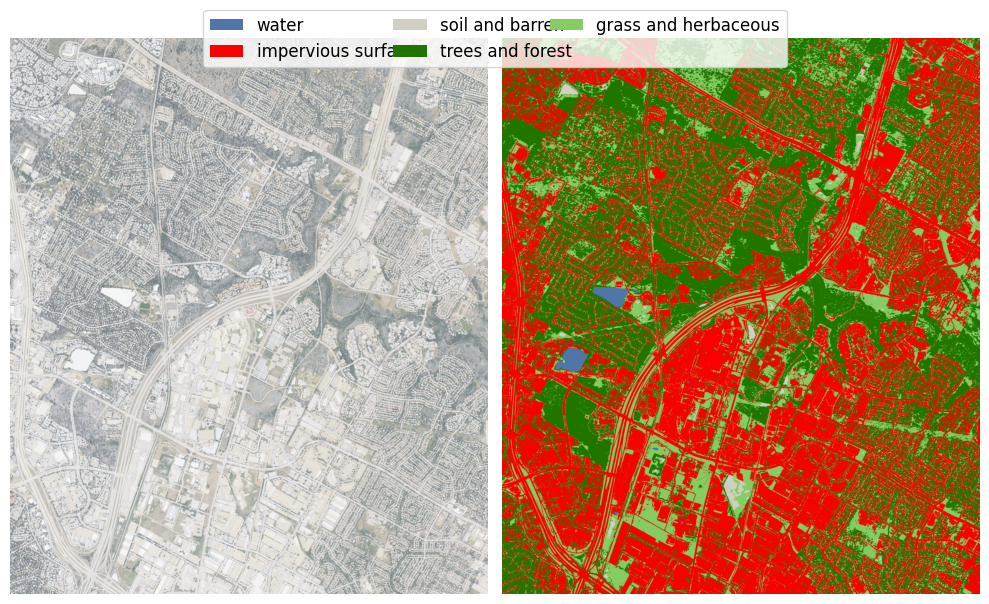

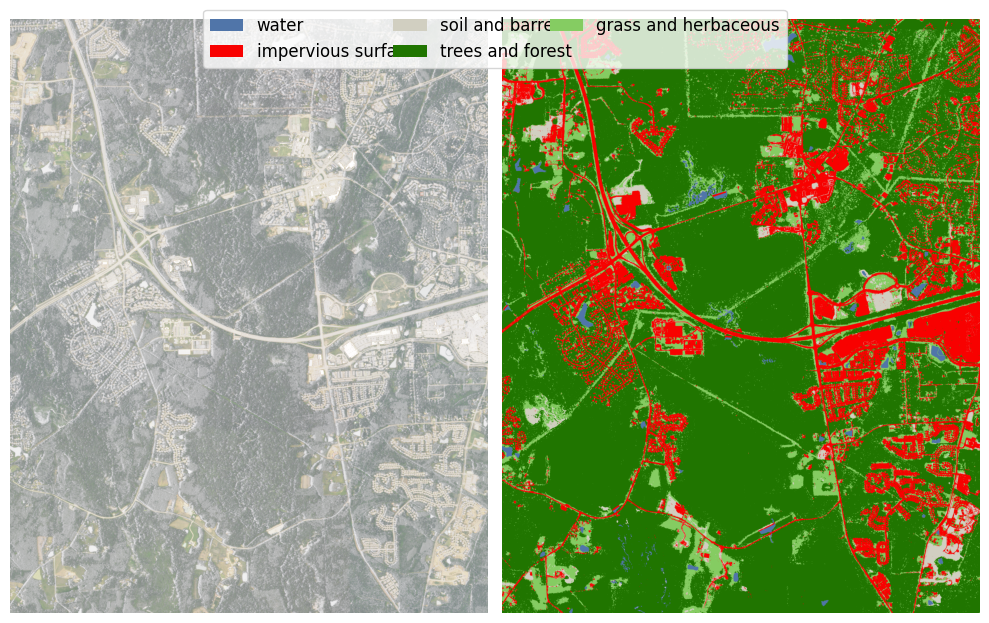

In [ ]:
dataset_config = {
    "data_dir": "./data/EnviroAtlas",
    "selection": "all"
}
dataset = EnviroAtlasDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(3);

In [5]:
dataset.data_distribution_table()

,Number of pixels
water,208323008.0
impervious surface,515142606.0
soil and barren,330021255.0
trees and forest,975366676.0
grass and herbaceous,370117297.0


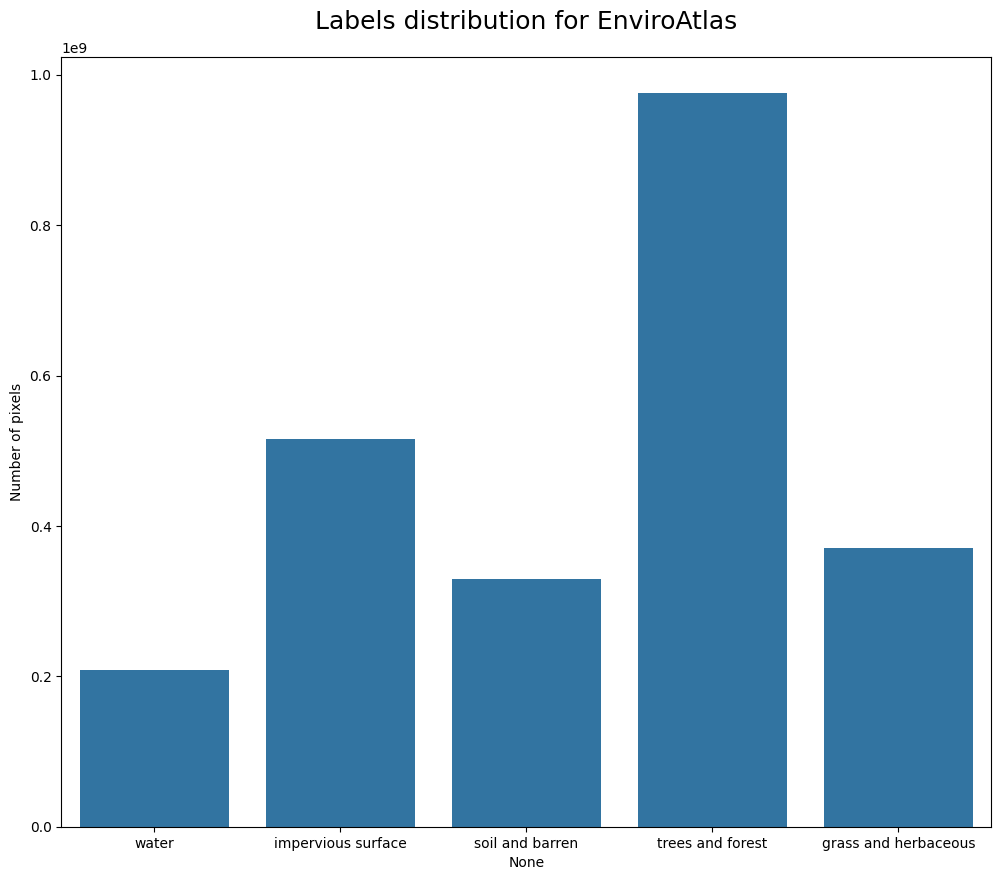

In [6]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 2,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/EnviroAtlas/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = EnviroAtlasDataset(train_dataset_config)
len(train_dataset)

10

## Create the model 

In [ ]:
epochs = 10
model_directory = "./data/EnviroAtlas"
model_config = {
    "num_classes": 5, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-11 08:01:15,677 INFO Starting training.
training: 100%|██████████| 5/5 [13:08<00:00, 157.65s/it]
2025-03-11 08:14:24,018 INFO epoch: 1, time: 789, loss:  0.70469
testing on train set: 100%|██████████| 5/5 [13:06<00:00, 157.36s/it]
2025-03-11 08:27:32,852 INFO IOU:0.030279576105011714, IOU mean:0.04250761543132327, IOU per Class:[0.04225573 0.02672045 0.00087293 0.1350278  0.00766117]
training: 100%|██████████| 5/5 [13:08<00:00, 157.75s/it]
2025-03-11 08:40:41,609 INFO epoch: 2, time: 789, loss:  0.68774
testing on train set: 100%|██████████| 5/5 [13:10<00:00, 158.09s/it]
2025-03-11 08:53:52,081 INFO IOU:0.04392994313075069, IOU mean:0.06739690183998603, IOU per Class:[0.09621432 0.02891802 0.00078412 0.20211727 0.00895078]
training: 100%|██████████| 5/5 [13:10<00:00, 158.01s/it]
2025-03-11 09:07:02,161 INFO epoch: 3, time: 790, loss:  0.67761
testing on train set: 100%|██████████| 5/5 [13:15<00:00, 159.01s/it]
2025-03-11 09:20:17,209 INFO IOU:0.0679684530467278, IOU mean:0.0785

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/EnviroAtlas/val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = EnviroAtlasDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/EnviroAtlas/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

23


2025-03-11 12:24:28,548 INFO Loading checkpoint /home/dragik/data/FAIR_EO/EnviroAtlas/checkpoint.pth.tar
2025-03-11 12:24:29,019 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/EnviroAtlas/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 6/6 [28:03<00:00, 280.59s/it]  


[{'IOU': 0.06507897337780727,
  'IOU mean': 0.04144671242645393,
  'IOU per Class': array([0.03308642, 0.02975765, 0.        , 0.13540673, 0.00898275])}]

## Predictions

2025-03-11 13:26:46,274 INFO Loading checkpoint /home/dragik/data/FAIR_EO/EnviroAtlas/checkpoint.pth.tar
2025-03-11 13:26:46,704 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/EnviroAtlas/checkpoint.pth.tar at epoch 11


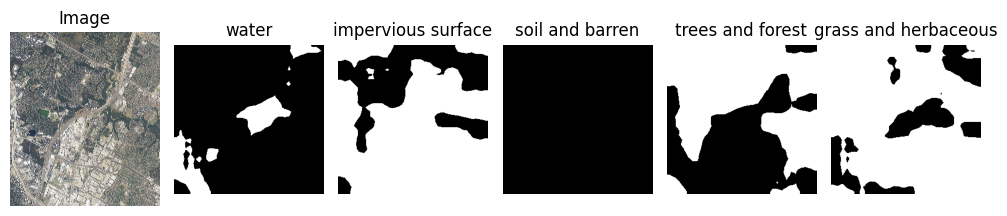

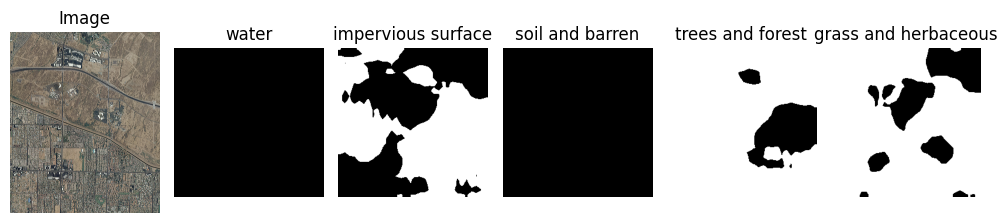

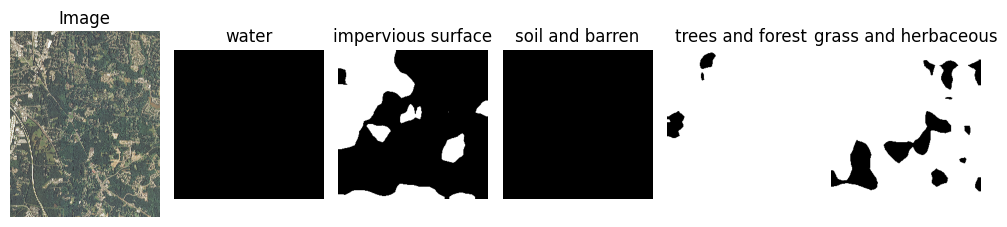

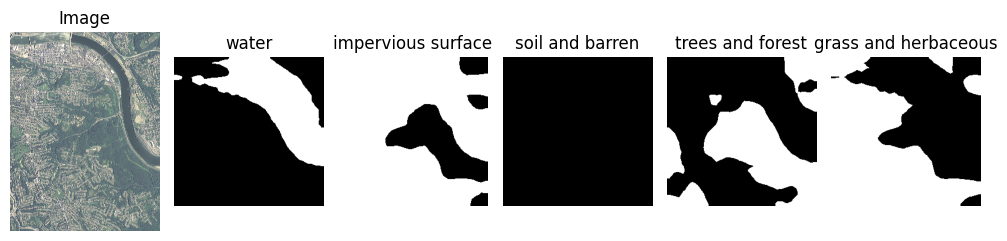

In [ ]:
model_path = "./data/EnviroAtlas/checkpoint.pth.tar"
labels = ["water","impervious surface","soil and barren","trees and forest","grass and herbaceous"]
transform1 = ResizeToTensor()
transform2 = MinMaxNormTranspose()
model.load_model(model_path)

image = image_loader('./data/EnviroAtlas/test/images/3009735_sw_a_naip.tif')
RGB = image[:,:,0:3]
fig = model.predict_masks(RGB, labels, transform1, transform2)

image = image_loader('./data/EnviroAtlas/test/images/3311117_sw_a_naip.tif')
RGB = image[:,:,0:3]
fig = model.predict_masks(RGB, labels, transform1, transform2)

image = image_loader('./data/EnviroAtlas/test/images/3507802_nw_a_naip.tif')
RGB = image[:,:,0:3]
fig = model.predict_masks(RGB, labels, transform1, transform2)

image = image_loader('./data/EnviroAtlas/test/images/4007933_sw_a_naip.tif')
RGB = image[:,:,0:3]
fig = model.predict_masks(RGB, labels, transform1, transform2)